# Don't Get Kicked — Neural network (PyTorch) solution


## Solution overview
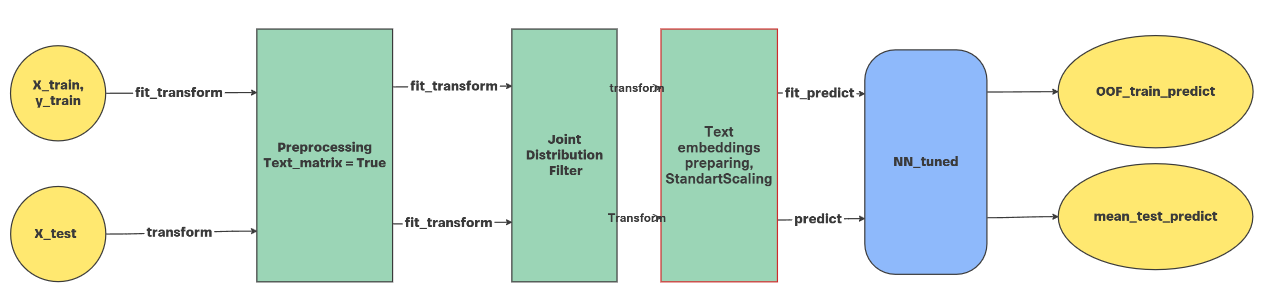

### 1. Feature engineering (`Preprocessing`)
Fitted on the training part of every fold only (no label leakage):
- **Price cleaning** – the 8 MMR price columns, `WarrantyCost` and `VehBCost` contain garbage (values < 100, NaN). Garbage is replaced by the train mean and marked with `*_is_trash` flags (flags that are highly correlated by Cramér's V are dropped).
- **Relative features** – drift between acquisition and current MMR prices, costs relative to the auction clean price, mileage per year of age.
- **Stacked factors** – small linear models turned into features: `price_factor` (polynomial logistic regression on prices), `Date_factor` (polynomial ridge on the purchase-date bucket), `text_factor` (logistic regression on Make/Model/Trim/SubModel tokens).
- Missing categories become an explicit `init_None` category.

### 2. Train/test shift control (`JointDistributionFilter`)
Values and categories that are rare in the train **or** in the test sample (share / quantile density below a threshold) are replaced by NaN, so the model never relies on values it cannot see consistently in both samples. Thresholds are tuned together with the model.

### 3. Network inputs (`NNFeatures`)
- **Text** – the binary token matrix `text__*` (rare tokens are removed by the JDF).
- **Categorical** – pandas `category` columns; `None`/unknown values get their own level; columns with more than 4 levels are embedded, the rest are one-hot encoded.
- **Continuous** – everything else; NaN is replaced with the train mean, then standardised.

### 4. Architecture
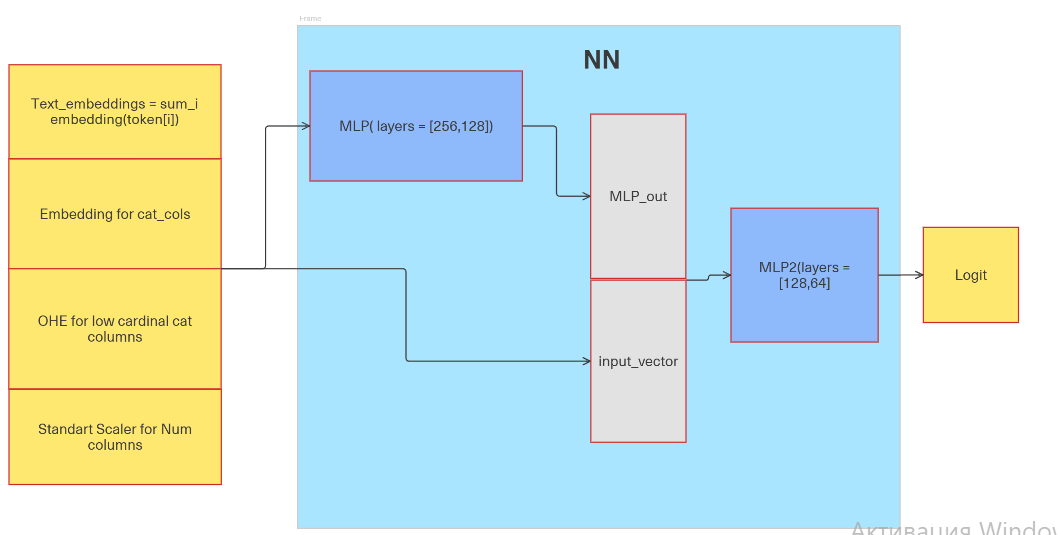
1. text matrix → `Linear(T → text_emb_dim, no bias)` (equal to summing token embeddings; optionally divided by the number of tokens) → `Linear(→ text_out_dim)` + activation + dropout;
2. embedded categoricals → `Linear(→ cat_out_dim)` + activation + dropout;
3. concatenate `[text, categorical, one-hot, continuous]`;
4. **MLP1** (`hidden1`: Linear → BatchNorm → activation, dropout) on the concatenation;
5. concatenate `[MLP1 output, step-3 vector]` → **MLP2** (`hidden2`) → one logit; loss `BCEWithLogitsLoss`, optimiser Adam, fixed number of epochs (`N_EPOCHS`, no early stopping).

### Hyper-parameter search (done offline)
Optuna on one fold tunes the embedding/hidden sizes, activation, dropout, learning rate, weight decay; `Preprocessing` and the `JointDistributionFilter` use default parameters. `CFG` below is the saved `nn_config.json`; `N_EPOCHS` is the epoch of the best CV checkpoint.

### Cross-validation scheme
5 stratified folds (`random_state=42`). In every fold the whole pipeline is fitted on the training part; test predictions of the 5 fold models are averaged. Out-of-fold ROC AUC is printed as a sanity check.


In [1]:
SEED, K = 42, 5
TRAIN_PATH = "../dont_get_kicked/datasets/training.csv"
TEST_PATH = "../dont_get_kicked/datasets/test.csv"
OUT_PATH = "nn_kaggle_submission.csv"
N_EPOCHS = 26   # epoch of the chosen checkpoint

CFG = {
  "text_emb_dim": 64,
  "cat_emb_dim": 128,
  "normalize_text": False,
  "activation": "selu",
  "dropout": 0.0013172639834241986,
  "text_out_dim": 8,
  "cat_out_dim": 4,
  "hidden1": [
    256,
    128
  ],
  "hidden2": [
    128,
    64
  ],
  "lr": 0.005293297998444228,
  "batch_size": 256,
  "weight_decay": 3.4483621694375005e-05,
  "best_tuning_auc": 0.7866515895192212,
  "best_epoch": 21,
  "n_trials": 40,
  "max_epochs": 40,
  "early_stop_patience": 10,
  "lr_scheduler_patience": 100
}

## Code: preprocessing classes (copied from the project)

In [2]:
import re
from collections import Counter
from typing import Optional

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

MMR_COLS = ['MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice', 'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice', 'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice']
NUMER_COLS = MMR_COLS + ['WarrantyCost', 'VehBCost']
CAT_COLS = ['Auction', 'BYRNO', 'VNZIP1', 'VNST', 'VehYear', 'Make', 'Model', 'Trim', 'SubModel', 'WheelType', 'Size', 'Color', 'PRIMEUNIT']
TEXT_COLS = ['Make', 'Model', 'Trim', 'SubModel']
DEFAULT_JDF_NUM_COLS = ['WarrantyCost', 'VehBCost', 'REL_DRIFT_RET_CLEAN', 'REL_DRIFT_RET_AVG', 'REL_DRIFT_AUC_AVG', 'REL_WarrantyCost', 'REL_VehBCost', 'VehOdo', 'VEHODO/VEHICLEAGE']
DEFAULT_JDF_CAT_COLS = list(CAT_COLS)
TOKEN_RE = re.compile('[a-z0-9]+')
PURCH_DATE_ORIGIN = pd.Timestamp('2009-01-05')

class Preprocessing(BaseEstimator, TransformerMixin):

    def __init__(self, mmr_cols: Optional[list]=None, numer_cols: Optional[list]=None, cat_cols: Optional[list]=None, text_cols: Optional[list]=None, price_trash_threshold: float=100.0, cramer_v_min: float=0.5, price_pipeline_degree: int=3, price_pipeline_alpha: float=0.007, text_min_count_train: int=100, text_logreg_C: float=65.0, add_text_binary_matrix: bool=False, date_pipeline_degree: int=13, date_pipeline_alpha: float=0.007, date_days: int=14, min_flag_count: int=500, weekday_type: Optional[str]=None):
        self.mmr_cols = list(mmr_cols) if mmr_cols is not None else list(MMR_COLS)
        self.numer_cols = list(numer_cols) if numer_cols is not None else list(NUMER_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(CAT_COLS)
        self.text_cols = list(text_cols) if text_cols is not None else list(TEXT_COLS)
        self.price_trash_threshold = price_trash_threshold
        self.cramer_v_min = cramer_v_min
        self.price_pipeline_degree = price_pipeline_degree
        self.price_pipeline_alpha = price_pipeline_alpha
        self.text_min_count_train = text_min_count_train
        self.text_logreg_C = text_logreg_C
        self.add_text_binary_matrix = add_text_binary_matrix
        self.date_pipeline_degree = date_pipeline_degree
        self.date_pipeline_alpha = date_pipeline_alpha
        self.date_days = date_days
        self.min_flag_count = min_flag_count
        self.weekday_type = weekday_type
        self.numer_cols_means = {}
        self.text_vocab = set()
        self.text_model = None
        self.text_vector_names = []
        self.price_pipeline = None
        self.date_ppl = None
        self.trash_flag_cols = []

    @staticmethod
    def _cramers_v(x, y):
        x = np.asarray(x)
        y = np.asarray(y)
        confusion = pd.crosstab(x, y)
        try:
            from scipy.stats import chi2_contingency
            chi2, _, _, _ = chi2_contingency(confusion.values)
        except Exception:
            chi2 = 0.0
        n = confusion.values.sum()
        phi2 = chi2 / n
        r, k = confusion.shape
        phi2corr = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
        rcorr = r - (r - 1) ** 2 / (n - 1)
        kcorr = k - (k - 1) ** 2 / (n - 1)
        denom = min(kcorr - 1, rcorr - 1)
        if denom <= 0:
            return 0.0
        return np.sqrt(phi2corr / denom)

    @staticmethod
    def _build_text(X):
        return (X['Make'].fillna('').astype(str) + ' ' + X['Model'].fillna('').astype(str) + ' ' + X['Trim'].fillna('').astype(str) + ' ' + X['SubModel'].fillna('').astype(str)).str.lower()

    @classmethod
    def _token_lists(cls, X):
        text = cls._build_text(X)
        return text.map(lambda s: list(dict.fromkeys(TOKEN_RE.findall(s)))).tolist()

    def _token_matrix(self, token_lists):
        index = {t: j for j, t in enumerate(self.text_vector_names)}
        matrix = np.zeros((len(token_lists), len(index)), dtype=np.uint8)
        for i, toks in enumerate(token_lists):
            for t in toks:
                j = index.get(t)
                if j is not None:
                    matrix[i, j] = 1
        return matrix

    def _trash_mask(self, s):
        return (s < self.price_trash_threshold) | s.isna()

    def _clean_numeric(self, X):
        X_num = X[self.numer_cols].copy().astype(float)
        for col in self.numer_cols:
            X_num.loc[self._trash_mask(X_num[col]), col] = self.numer_cols_means[col]
        return X_num

    def _date_frame(self, X):
        return pd.DataFrame({'PurchDate': (X['PurchDate'] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)})

    def _fill_cat_none(self, X):
        for col in self.cat_cols:
            if col in X.columns:
                X[col] = X[col].fillna('init_None').astype(str)
        return X

    def fit(self, X, y):
        X = X.copy()
        X['PurchDate'] = pd.to_datetime(X['PurchDate'])
        y_arr = y.values.astype(float) if hasattr(y, 'values') else np.asarray(y, dtype=float)
        self.numer_cols_means = {}
        for col in self.numer_cols:
            self.numer_cols_means[col] = X.loc[~self._trash_mask(X[col]), col].mean()
        trash_flags = {f'{col}_is_trash': self._trash_mask(X[col]).astype(int) for col in self.numer_cols}
        flag_cols = list(trash_flags.keys())
        keep_flags = list(flag_cols)
        for i, c1 in enumerate(flag_cols):
            for c2 in flag_cols[i + 1:]:
                v = self._cramers_v(trash_flags[c1], trash_flags[c2])
                if v > self.cramer_v_min:
                    if trash_flags[c1].mean() < trash_flags[c2].mean():
                        if c1 in keep_flags:
                            keep_flags.remove(c1)
                    elif c2 in keep_flags:
                        keep_flags.remove(c2)
        for c in list(keep_flags):
            if trash_flags[c].sum() < self.min_flag_count:
                keep_flags.remove(c)
        self.trash_flag_cols = keep_flags
        X_num = self._clean_numeric(X)
        self.price_pipeline = Pipeline([('SS1', StandardScaler()), ('PT', PolynomialFeatures(self.price_pipeline_degree, include_bias=False)), ('SS2', StandardScaler()), ('LR', LogisticRegression(C=100, max_iter=10000))]).fit(X_num, y_arr)
        self.date_ppl = Pipeline([('ss1', StandardScaler()), ('pt', PolynomialFeatures(degree=self.date_pipeline_degree, include_bias=False)), ('ss2', StandardScaler()), ('lr', Ridge(alpha=self.date_pipeline_alpha))]).fit(self._date_frame(X), y_arr)
        Xp = self._fill_cat_none(X.copy())
        token_lists = self._token_lists(Xp)
        token_counts = Counter((t for toks in token_lists for t in toks))
        thr = self.text_min_count_train
        if isinstance(thr, float):
            thr = thr * len(Xp)
        self.text_vocab = {t for t, c in token_counts.items() if c >= thr}
        self.text_vector_names = sorted(self.text_vocab)
        if self.text_vector_names:
            token_matrix = self._token_matrix(token_lists)
            self.text_model = LogisticRegression(C=self.text_logreg_C, max_iter=5000)
            self.text_model.fit(token_matrix, y_arr)
        else:
            self.text_model = None
        return self

    def transform(self, X):
        X = X.copy()
        X['PurchDate'] = pd.to_datetime(X['PurchDate'])
        X = self._fill_cat_none(X)
        X_trans = self._clean_numeric(X)
        divisor = X_trans['MMRAcquisitionAuctionCleanPrice'].copy()
        X_trans['price_factor'] = self.price_pipeline.predict_proba(X_trans[self.numer_cols])[:, 1]
        for col in self.cat_cols:
            if col in X.columns:
                X_trans[col] = X[col]
        for col_base in self.numer_cols:
            flag_name = f'{col_base}_is_trash'
            if flag_name in self.trash_flag_cols:
                X_trans[flag_name] = self._trash_mask(X[col_base]).astype(int)
        token_matrix = None
        if self.text_vector_names:
            token_matrix = self._token_matrix(self._token_lists(X))
        if self.add_text_binary_matrix and token_matrix is not None:
            ohe_df = pd.DataFrame(token_matrix, columns=[f'text__{t}' for t in self.text_vector_names], index=X.index)
            X_trans = pd.concat([X_trans, ohe_df], axis=1)
        X_trans['REL_DRIFT_RET_CLEAN'] = (X_trans['MMRCurrentRetailCleanPrice'] - X_trans['MMRAcquisitonRetailCleanPrice']) / X_trans['MMRAcquisitonRetailCleanPrice']
        X_trans['REL_DRIFT_RET_AVG'] = (X_trans['MMRCurrentRetailAveragePrice'] - X_trans['MMRAcquisitionRetailAveragePrice']) / X_trans['MMRAcquisitionRetailAveragePrice']
        X_trans['REL_DRIFT_AUC_AVG'] = (X_trans['MMRCurrentAuctionAveragePrice'] - X_trans['MMRAcquisitionAuctionAveragePrice']) / X_trans['MMRAcquisitionAuctionAveragePrice']
        X_trans.drop(columns=self.numer_cols[:len(MMR_COLS)], inplace=True, errors='ignore')
        rel_cols = ['WarrantyCost', 'VehBCost']
        X_trans[['REL_' + col for col in rel_cols]] = X_trans[rel_cols].values / divisor.values.reshape(-1, 1)
        X_trans[['VehOdo', 'VehicleAge']] = X[['VehOdo', 'VehicleAge']]
        X_trans['VEHODO/VEHICLEAGE'] = X['VehOdo'] / (X['VehicleAge'] + 1)
        if self.text_model is not None and token_matrix is not None:
            X_trans['text_factor'] = self.text_model.predict_proba(token_matrix)[:, 1]
        X_trans['Date_factor'] = self.date_ppl.predict(self._date_frame(X))
        X_trans['date_days_count'] = ((X['PurchDate'] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)).astype('category')
        for col in self.cat_cols:
            if col in X_trans.columns:
                X_trans[col] = X_trans[col].astype('category')
        return X_trans

    def fit_transform(self, X, y=None, **fit_params):
        self.fit(X, y)
        return self.transform(X)

class JointDistributionFilter(TransformerMixin):

    def __init__(self, X_train, X_test=None, num_cols=None, cat_cols=None, dp: float=0.02, th_num_train: float=0.001, th_num_test: float=0.001, th_cat_train: float=0.005, th_cat_test: float=0.005, min_dx_frac: float=0.001, bin_prefix: str='text__', verbose: bool=False):
        self.dp = dp
        self.th_num_train = th_num_train
        self.th_num_test = th_num_test
        self.th_cat_train = th_cat_train
        self.th_cat_test = th_cat_test
        self.min_dx_frac = min_dx_frac
        self.bin_prefix = bin_prefix
        self.verbose = verbose
        self.num_cols = list(num_cols) if num_cols is not None else list(DEFAULT_JDF_NUM_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(DEFAULT_JDF_CAT_COLS)
        self.train_profiles = {}
        self.test_profiles = {}
        self.bin_train_freq = {}
        self.bin_test_freq = {}
        self.bin_cols_to_drop_ = []
        self._build_profiles(X_train, is_test=False)
        if X_test is not None:
            self._build_profiles(X_test, is_test=True)
        self._build_bin_freqs(X_train, X_test)

    def _num_profile(self, s):
        x = pd.to_numeric(s, errors='coerce').dropna()
        n = len(x)
        if n == 0:
            return None
        shares = x.value_counts(normalize=True)
        heavy = shares[shares >= self.dp]
        heavy_shares = heavy.to_dict()
        rest = x[~x.isin(heavy.index)].values
        profile = {'heavy': heavy_shares, 'cx': None, 'log_cy': None}
        if len(rest) < 2:
            return profile
        rng = rest.max() - rest.min()
        if rng <= 0:
            return profile
        n_bins = int(round(1 / self.dp))
        edges = np.quantile(rest, np.linspace(0, 1, n_bins + 1))
        dx = np.maximum(np.diff(edges), self.min_dx_frac * rng)
        dens = 1.0 / n_bins / dx * rng
        centers = (edges[:-1] + edges[1:]) / 2.0
        cx = np.concatenate([[edges[0]], centers, [edges[-1]]])
        cy = np.concatenate([[dens[0]], dens, [dens[-1]]])
        profile['cx'], profile['log_cy'] = (cx, np.log(cy))
        return profile

    def _build_profiles(self, df, is_test: bool=False):
        profiles = {}
        for col in self.num_cols:
            if col in df.columns:
                p = self._num_profile(df[col])
                if p is not None:
                    profiles[col] = p
        for col in self.cat_cols:
            if col in df.columns:
                profiles[col] = df[col].value_counts(normalize=True).to_dict()
        if is_test:
            self.test_profiles = profiles
        else:
            self.train_profiles = profiles

    def _build_bin_freqs(self, X_train, X_test=None):
        bin_cols = [c for c in X_train.columns if str(c).startswith(self.bin_prefix)]
        self.bin_train_freq = {c: float(pd.to_numeric(X_train[c], errors='coerce').fillna(0).mean()) for c in bin_cols}
        self.bin_test_freq = {}
        if X_test is not None:
            self.bin_test_freq = {c: float(pd.to_numeric(X_test[c], errors='coerce').fillna(0).mean()) for c in bin_cols if c in X_test.columns}
        drop = []
        for c in bin_cols:
            if self.bin_train_freq[c] < self.th_cat_train:
                drop.append(c)
            elif X_test is not None and self.bin_test_freq.get(c, 0.0) < self.th_cat_test:
                drop.append(c)
        self.bin_cols_to_drop_ = drop
        if self.verbose:
            print(f'binary {self.bin_prefix}* columns: dropping {len(drop)} of {len(bin_cols)}')

    @staticmethod
    def _num_pass_mask(x, profile, th_num, th_heavy):
        if profile['cx'] is None:
            mask = np.zeros(len(x), dtype=bool)
        else:
            log_d = np.interp(x, profile['cx'], profile['log_cy'], left=-np.inf, right=-np.inf)
            mask = np.exp(log_d) >= th_num
        if profile['heavy']:
            share = pd.Series(x).map(profile['heavy']).values
            is_heavy = ~np.isnan(share)
            mask = np.where(is_heavy, np.nan_to_num(share) >= th_heavy, mask)
        return mask

    @staticmethod
    def _cat_share(values, profile):
        s = pd.Series(np.asarray(values, dtype=object))
        return s.map(profile).astype(float).fillna(0.0).values

    def _surviving_categories(self, col):
        cats = []
        test_profile = self.test_profiles.get(col)
        for k, share in self.train_profiles[col].items():
            if share < self.th_cat_train or share <= 0:
                continue
            if test_profile is not None and test_profile.get(k, 0.0) < self.th_cat_test:
                continue
            cats.append(k)
        return cats

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in self.num_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            x = pd.to_numeric(X_out[col], errors='coerce').astype(float).values
            final = self._num_pass_mask(x, self.train_profiles[col], self.th_num_train, self.th_cat_train)
            if col in self.test_profiles:
                final &= self._num_pass_mask(x, self.test_profiles[col], self.th_num_test, self.th_cat_test)
            was_nan = np.isnan(x)
            out = x.copy()
            out[~final] = np.nan
            X_out[col] = out
            if self.verbose:
                print(f'{col}: masked {(~final & ~was_nan).mean():.2%} of values')
        for col in self.cat_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            vals = X_out[col].values
            final = self._cat_share(vals, self.train_profiles[col]) >= self.th_cat_train
            if col in self.test_profiles:
                final &= self._cat_share(vals, self.test_profiles[col]) >= self.th_cat_test
            cats = self._surviving_categories(col)
            X_out[col] = pd.Series(np.asarray(X_out[col].values, dtype=object), index=X_out.index).where(final).astype(pd.CategoricalDtype(categories=cats))
            if self.verbose:
                print(f'{col}: masked {(~final).mean():.2%} of values')
        drop_cols = [c for c in self.bin_cols_to_drop_ if c in X_out.columns]
        if drop_cols:
            X_out = X_out.drop(columns=drop_cols)
        return X_out

## Code: network input builder

In [3]:
TEXT_PREFIX = 'text__'
EMBED_MIN_LEVELS = 4

class NNFeatures:

    def fit(self, X: pd.DataFrame):
        cols = list(X.columns)
        self.text_cols = [c for c in cols if str(c).startswith(TEXT_PREFIX)]
        self.cat_cols = [c for c in cols if isinstance(X[c].dtype, pd.CategoricalDtype)]
        special = set(self.text_cols) | set(self.cat_cols)
        self.cont_cols = [c for c in cols if c not in special]
        self.cat_levels = {c: list(X[c].cat.categories) for c in self.cat_cols}
        self.cat_card = {c: len(self.cat_levels[c]) + 1 for c in self.cat_cols}
        self.embed_cols = [c for c in self.cat_cols if self.cat_card[c] > EMBED_MIN_LEVELS]
        self.ohe_cols = [c for c in self.cat_cols if self.cat_card[c] <= EMBED_MIN_LEVELS]
        cont = self._cont_frame(X)
        self.cont_means = cont.mean().fillna(0.0)
        self.scaler = StandardScaler().fit(cont.fillna(self.cont_means).to_numpy(dtype=np.float64))
        return self

    def _cont_frame(self, X):
        if not self.cont_cols:
            return pd.DataFrame(index=X.index)
        cont = X[self.cont_cols].apply(pd.to_numeric, errors='coerce').astype(float)
        return cont.replace([np.inf, -np.inf], np.nan)

    def _cat_codes(self, X, col):
        levels = self.cat_levels[col]
        codes = pd.Categorical(X[col].astype(object), categories=levels).codes.astype(np.int64)
        return np.where(codes < 0, len(levels), codes)

    def transform(self, X: pd.DataFrame):
        n = len(X)
        if self.text_cols:
            text = X[self.text_cols].apply(pd.to_numeric, errors='coerce').fillna(0).to_numpy(dtype=np.float32)
        else:
            text = np.zeros((n, 0), dtype=np.float32)
        cat_ids = {col: self._cat_codes(X, col) for col in self.embed_cols}
        ohe_blocks = []
        for col in self.ohe_cols:
            codes = self._cat_codes(X, col)
            block = np.zeros((n, self.cat_card[col]), dtype=np.float32)
            block[np.arange(n), codes] = 1.0
            ohe_blocks.append(block)
        ohe = np.hstack(ohe_blocks) if ohe_blocks else np.zeros((n, 0), dtype=np.float32)
        cont = self._cont_frame(X).fillna(self.cont_means).to_numpy(dtype=np.float64)
        cont = self.scaler.transform(cont).astype(np.float32) if cont.shape[1] else np.zeros((n, 0), dtype=np.float32)
        return {'text': text, 'cat_ids': cat_ids, 'ohe': ohe, 'cont': cont, 'text_dim': text.shape[1], 'embed_cols': list(self.embed_cols), 'embed_cards': [self.cat_card[c] for c in self.embed_cols], 'ohe_dim': ohe.shape[1], 'cont_dim': cont.shape[1]}

## Code: model and training

In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ACTIVATIONS = {'relu': nn.ReLU, 'gelu': nn.GELU, 'tanh': nn.Tanh, 'selu': nn.SELU, 'leaky_relu': nn.LeakyReLU, 'elu': nn.ELU}

def build_mlp(in_dim, hidden, activation, dropout):
    layers = []
    prev = in_dim
    for width in hidden:
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(prev, width))
        layers.append(nn.BatchNorm1d(width))
        layers.append(ACTIVATIONS[activation]())
        prev = width
    return nn.Sequential(*layers)

class NNModel(nn.Module):

    def __init__(self, config, text_dim, embed_cards, ohe_dim, cont_dim, embed_cols):
        super().__init__()
        self.config = config
        self.cat_cols = list(embed_cols)
        activation = config['activation']
        dropout = float(config['dropout'])
        text_emb_dim = int(config['text_emb_dim'])
        cat_emb_dim = int(config['cat_emb_dim'])
        text_out_dim = int(config.get('text_out_dim', 8))
        cat_out_dim = int(config.get('cat_out_dim', 2))
        self.text_in = text_dim
        if text_dim:
            self.text_emb = nn.Linear(text_dim, text_emb_dim, bias=False)
            self.text_out = nn.Sequential(nn.Linear(text_emb_dim, text_out_dim), ACTIVATIONS[activation](), nn.Dropout(dropout))
        else:
            text_out_dim = 0
        if embed_cards:
            self.cat_embs = nn.ModuleList([nn.Embedding(card, cat_emb_dim) for card in embed_cards])
            self.cat_out = nn.Sequential(nn.Linear(cat_emb_dim * len(embed_cards), cat_out_dim), ACTIVATIONS[activation](), nn.Dropout(dropout))
        else:
            self.cat_embs = nn.ModuleList()
            cat_out_dim = 0
        self.ohe_dim = ohe_dim
        self.cont_dim = cont_dim
        in_dim = text_out_dim + cat_out_dim + ohe_dim + cont_dim
        self.mlp1 = build_mlp(in_dim, config['hidden1'], activation, dropout)
        hidden1_out = config['hidden1'][-1]
        self.mlp2 = build_mlp(hidden1_out + in_dim, config['hidden2'], activation, dropout)
        self.out = nn.Linear(config['hidden2'][-1], 1)

    def forward(self, batch):
        parts = []
        if self.text_in:
            text = batch['text']
            t = self.text_emb(text)
            if self.config['normalize_text']:
                t = t / text.sum(dim=1, keepdim=True).clamp(min=1.0)
            parts.append(self.text_out(t))
        if len(self.cat_embs):
            cat_flat = torch.cat([emb(batch['cat_ids'][col]) for emb, col in zip(self.cat_embs, self.cat_cols)], dim=1)
            parts.append(self.cat_out(cat_flat))
        if self.ohe_dim:
            parts.append(batch['ohe'])
        if self.cont_dim:
            parts.append(batch['cont'])
        x6 = torch.cat(parts, dim=1)
        h = self.mlp1(x6)
        x7 = torch.cat([h, x6], dim=1)
        return self.out(self.mlp2(x7)).squeeze(-1)

def to_batch(spec):
    return {"text": torch.as_tensor(spec["text"], dtype=torch.float32, device=DEVICE),
            "cat_ids": {c: torch.as_tensor(v, dtype=torch.long, device=DEVICE) for c, v in spec["cat_ids"].items()},
            "ohe": torch.as_tensor(spec["ohe"], dtype=torch.float32, device=DEVICE),
            "cont": torch.as_tensor(spec["cont"], dtype=torch.float32, device=DEVICE)}

def train_nn(cfg, spec, y, epochs):
    torch.manual_seed(SEED)
    model = NNModel(cfg, spec["text_dim"], spec["embed_cards"], spec["ohe_dim"], spec["cont_dim"], spec["embed_cols"]).to(DEVICE)
    b, yt = to_batch(spec), torch.as_tensor(y, dtype=torch.float32, device=DEVICE)
    cols = model.cat_cols
    cat = torch.stack([b["cat_ids"][c] for c in cols], 1) if cols else torch.zeros((len(yt), 0), dtype=torch.long, device=DEVICE)
    loader = DataLoader(TensorDataset(b["text"], cat, b["ohe"], b["cont"], yt), batch_size=int(cfg["batch_size"]), shuffle=True, drop_last=True)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg.get("weight_decay", 0.0))
    loss_fn = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        model.train()
        for text, cat_ids, ohe, cont, yb in loader:
            opt.zero_grad()
            batch = {"text": text, "cat_ids": {c: cat_ids[:, i] for i, c in enumerate(cols)}, "ohe": ohe, "cont": cont}
            loss_fn(model(batch), yb).backward()
            opt.step()
    return model

@torch.no_grad()
def predict_nn(model, spec):
    model.eval()
    return torch.sigmoid(model(to_batch(spec))).cpu().numpy()

## Data

In [5]:
train, test = pd.read_csv(TRAIN_PATH), pd.read_csv(TEST_PATH)
train["PurchDate"], test["PurchDate"] = pd.to_datetime(train["PurchDate"]), pd.to_datetime(test["PurchDate"])
y = train["IsBadBuy"]
X, X_test, ref_id = train.drop(columns=["IsBadBuy", "RefId"]), test.drop(columns=["RefId"]), test["RefId"]
folds = list(StratifiedKFold(K, shuffle=True, random_state=SEED).split(X, y))
print(X.shape, X_test.shape, "positive rate:", round(y.mean(), 4))

(72983, 32) (48707, 32) positive rate: 0.123


## Training: 5 folds, pipeline fitted inside every fold, averaged test predictions

In [6]:
oof, test_pred = np.zeros(len(X)), np.zeros(len(X_test))
for k, (tr, va) in enumerate(folds):
    prep = Preprocessing(add_text_binary_matrix=True).fit(X.iloc[tr], y.iloc[tr])
    Xtr, Xva, Xte = (prep.transform(d) for d in (X.iloc[tr], X.iloc[va], X_test))
    jdf = JointDistributionFilter(Xtr, Xte)
    Xtr, Xva, Xte = (jdf.transform(d) for d in (Xtr, Xva, Xte))
    fe = NNFeatures().fit(Xtr)
    s_tr, s_va, s_te = (fe.transform(d) for d in (Xtr, Xva, Xte))
    model = train_nn(CFG, s_tr, y.iloc[tr].to_numpy(), N_EPOCHS)
    oof[va] = predict_nn(model, s_va)
    test_pred += predict_nn(model, s_te) / K
    print(f"fold {k}: text={s_tr['text_dim']} emb_cat={len(s_tr['embed_cols'])} ohe={s_tr['ohe_dim']} cont={s_tr['cont_dim']}, val AUC={roc_auc_score(y.iloc[va], oof[va]):.5f}")

fold 0: text=167 emb_cat=12 ohe=7 cont=14, val AUC=0.77920
fold 1: text=167 emb_cat=12 ohe=7 cont=14, val AUC=0.77357
fold 2: text=167 emb_cat=12 ohe=7 cont=14, val AUC=0.79005
fold 3: text=165 emb_cat=12 ohe=7 cont=14, val AUC=0.78512
fold 4: text=166 emb_cat=12 ohe=7 cont=14, val AUC=0.77525


## Submission

In [7]:
print("OOF ROC AUC:", round(roc_auc_score(y, oof), 5))
pd.DataFrame({"RefId": ref_id, "IsBadBuy": test_pred}).to_csv(OUT_PATH, index=False)
print("saved", OUT_PATH)

OOF ROC AUC: 0.77724
saved nn_kaggle_submission.csv


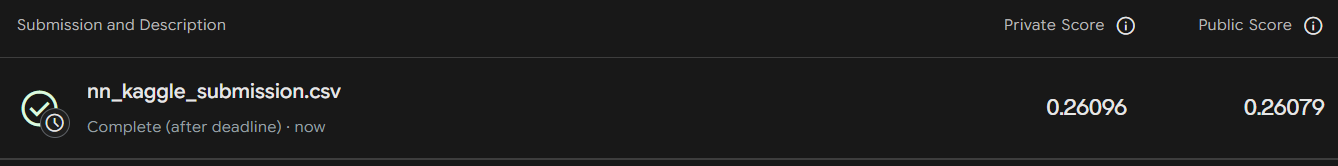